# Fake News Detection - Exploratory Data Analysis

**Objective:** Clean, preprocess, and explore the `Fake.csv` and `True.csv` article datasets
to understand the structure of the text, check class balance, and surface any patterns
(or data leakage risks) relevant to a later fake-news classification task.

**Datasets**
- `Fake.csv` — articles labeled as fake news
- `True.csv` — articles labeled as true/real news

In [26]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [27]:
import re
from collections import Counter

import nltk
from nltk.corpus import stopwords

In [28]:
import nltk
nltk.download("stopwords")
STOPWORDS = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\RIGHTEOUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Load and combine the data

Both files share the same schema. We add a `label` column before combining so the source of each row is preserved through cleaning.

In [29]:
fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

fake["label"] = "fake"
true["label"] = "true"

print(f"fake: {fake.shape[0]:,} rows | true: {true.shape[0]:,} rows")

df = pd.concat([fake, true], ignore_index=True)
print(f"combined: {df.shape[0]:,} rows x {df.shape[1]} columns")

fake: 23,481 rows | true: 21,417 rows
combined: 44,898 rows x 5 columns


In [30]:
df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",fake
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",fake
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",fake
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",fake
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",fake


## Initial data overview

In [31]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB


In [32]:
df.isnull().sum()

title      0
text       0
subject    0
date       0
label      0
dtype: int64

In [33]:
print("Class balance:")
df["label"].value_counts(normalize = True)*100

Class balance:


label
fake    52.298543
true    47.701457
Name: proportion, dtype: float64

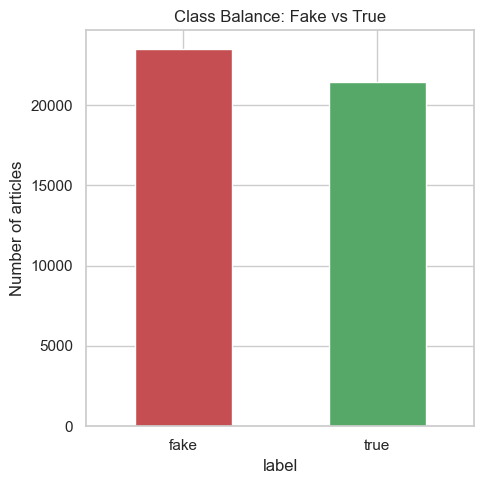

In [34]:
plt.figure(figsize=(5, 5))
df["label"].value_counts().plot(kind="bar", color=["#C44E52", "#55A868"])
plt.title("Class Balance: Fake vs True")
plt.ylabel("Number of articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


No missing values in any column, and the classes are reasonably balanced (~52% fake / 48% true) there is no severe class imbalance.

## Data cleaning

In [35]:
df_clean = df.copy()

# Check for exact duplicate articles
df_clean.duplicated(subset=["title", "text"]).sum()


np.int64(5793)

In [36]:
df_clean = df_clean.drop_duplicates(subset=["title", "text"]).reset_index(drop=True)

In [37]:
df_clean.duplicated(subset=["title", "text"]).sum()

np.int64(0)

In [38]:
# Check for short text length
df_clean["text_len_raw"] = df_clean["text"].str.len()
short_text = (df_clean["text_len_raw"] < 20).sum()
print(f"Rows with near-empty text body (<20 chars): {short_text}")

Rows with near-empty text body (<20 chars): 474


In [39]:
# flag them
df_clean["has_body_text"] = df_clean["text_len_raw"] >= 20
df_clean.groupby("label")["has_body_text"].mean().round(3)


label
fake    0.974
true    1.000
Name: has_body_text, dtype: float64

In [40]:
def is_parseable_date(value):
    try:
        pd.to_datetime(value)
        return True
    except (ValueError, TypeError):
        return False

df_clean["date_valid"] = df_clean["date"].apply(is_parseable_date)
print(f"Rows with an unparseable date: {(~df_clean['date_valid']).sum()}")
df_clean.loc[~df_clean["date_valid"], ["label", "title", "date"]].head()

Rows with an unparseable date: 6


,label,title,date
9358,fake,https://100percentfedup.com/served-roy-moore-v...,https://100percentfedup.com/served-roy-moore-v...
15504,fake,https://100percentfedup.com/video-hillary-aske...,https://100percentfedup.com/video-hillary-aske...
15505,fake,https://100percentfedup.com/12-yr-old-black-co...,https://100percentfedup.com/12-yr-old-black-co...
15836,fake,https://fedup.wpengine.com/wp-content/uploads/...,https://fedup.wpengine.com/wp-content/uploads/...
15837,fake,https://fedup.wpengine.com/wp-content/uploads/...,https://fedup.wpengine.com/wp-content/uploads/...


In [41]:
# Parse valid dates, leave the rest as NaT rather than guessing
df_clean["date_parsed"] = pd.to_datetime(df_clean["date"].where(df_clean["date_valid"]).str.strip(),format="mixed", errors="coerce")
print(f"Parsed date range: {df_clean['date_parsed'].min()} to {df_clean['date_parsed'].max()}")
df_clean.groupby("label")["date_parsed"].count() 

Parsed date range: 2015-03-31 00:00:00 to 2018-02-19 00:00:00


label
fake    17902
true    21197
Name: date_parsed, dtype: int64

In [42]:
## Text preprocessing

def clean_text(text):
    """Lowercase, strip URLs/punctuation/numbers, collapse whitespace."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)  
    text = re.sub(r"[^a-z\s]", " ", text)            
    text = re.sub(r"\s+", " ", text).strip()         
    return text

df_clean["text_processed"] = df_clean["text"].apply(clean_text)
df_clean["word_count"] = df_clean["text_processed"].apply(lambda t: len(t.split()))

df_clean[["text", "text_processed", "word_count"]].head(3)

,text,text_processed,word_count
0,Donald Trump just couldn t wish all Americans ...,donald trump just couldn t wish all americans ...,484
1,House Intelligence Committee Chairman Devin Nu...,house intelligence committee chairman devin nu...,315
2,"On Friday, it was revealed that former Milwauk...",on friday it was revealed that former milwauke...,598


## EDA — Subject breakdown

In [43]:
subject_by_label = pd.crosstab(df_clean["subject"], df_clean["label"])
subject_by_label


label,fake,true
subject,,
Government News,532,0
News,9050,0
US_News,783,0
left-news,705,0
politics,6838,0
politicsNews,0,11217
worldnews,0,9980


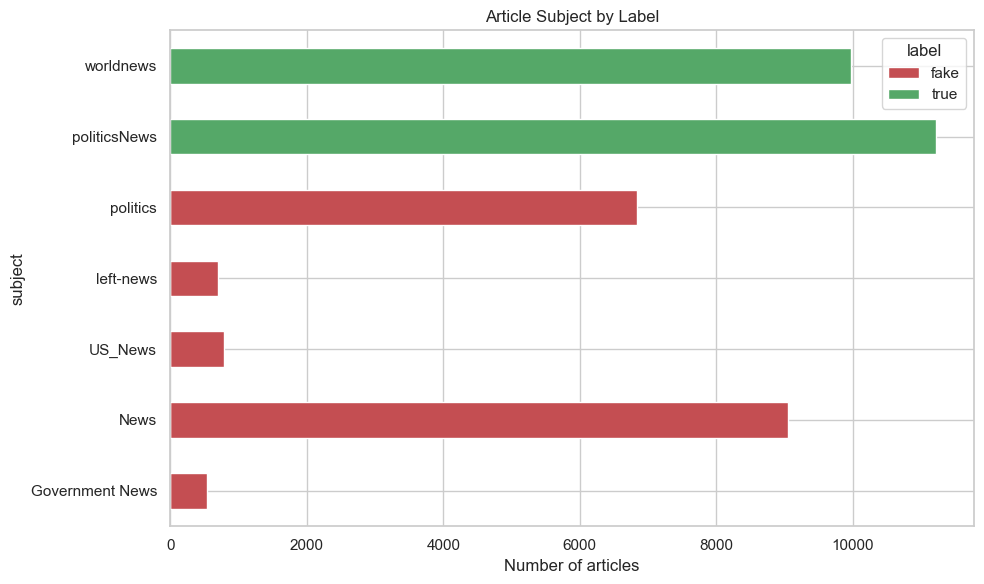

In [44]:
plt.figure(figsize=(10, 6))
subject_by_label.plot(kind="barh", stacked=True, color=["#C44E52", "#55A868"], ax=plt.gca())
plt.title("Article Subject by Label")
plt.xlabel("Number of articles")
plt.tight_layout()
plt.show()


**Critical finding — subject perfectly separates the two classes.** Every `subject` value in
the fake set (`News`, `politics`, `left-news`, `Government News`, `US_News`, `Middle-east`) is
completely disjoint from every `subject` value in the true set (`politicsNews`, `worldnews`).
This means `subject` is not a genuine content signal, it is an artifact of how the two files
were originally collected/labeled (all "true" articles came from Reuters via a `politicsNews`/
`worldnews` feed, all "fake" articles came from other sites categorized differently).

## EDA - Text length

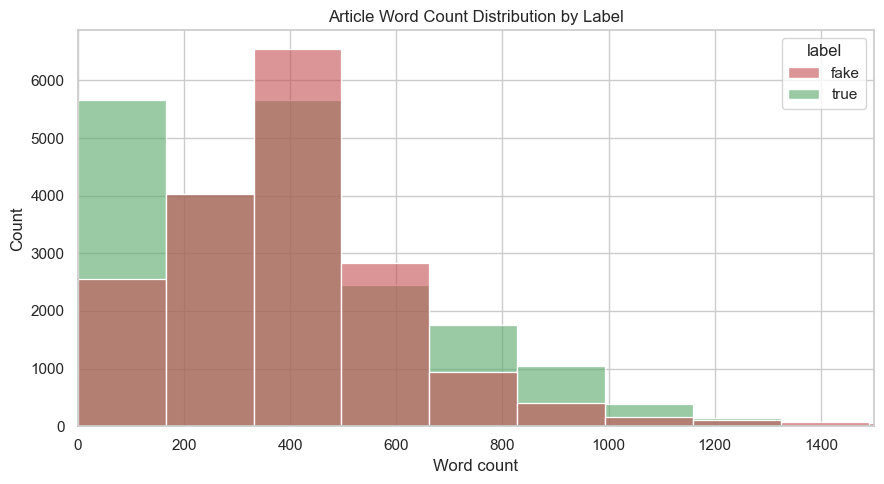

,mean,50%,min,max
label,,,,
fake,421.896024,378.0,0.0,8281.0
true,387.422324,360.0,0.0,5245.0


In [45]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="word_count", hue="label", bins=50, palette={"fake": "#C44E52", "true": "#55A868"}, alpha=0.6)
plt.xlim(0, 1500)
plt.title("Article Word Count Distribution by Label")
plt.xlabel("Word count")
plt.tight_layout()
plt.show()

df_clean.groupby("label")["word_count"].describe()[["mean", "50%", "min", "max"]]


True articles run noticeably longer on average than fake articles, consistent with Reuters-style wire reporting versus shorter opinion/blog-style fake content.

## EDA - Most common words per class

Using the cleaned text and English stopword removal to surface the most distinctive vocabulary in each class.

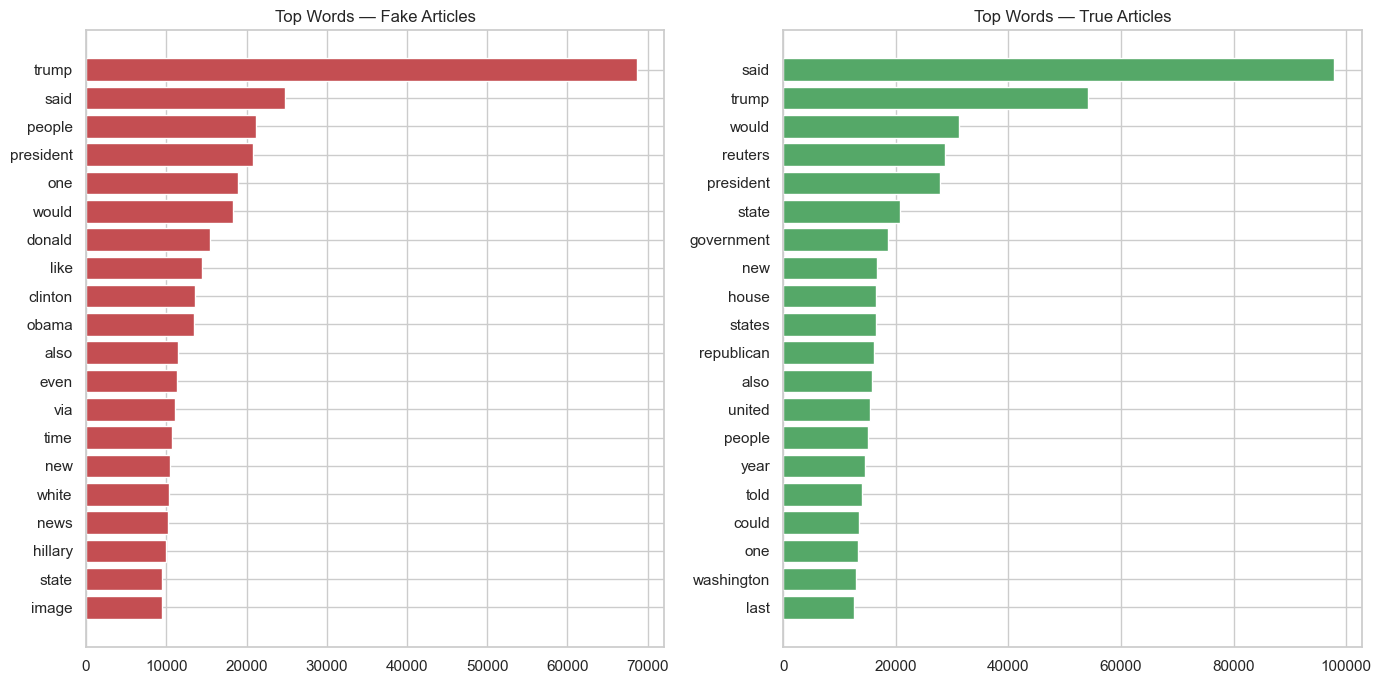

In [46]:
def top_words(texts, n=20):
    words = []
    for t in texts:
        words.extend([w for w in t.split() if w not in STOPWORDS and len(w) > 2])
    return Counter(words).most_common(n)

fake_top = top_words(df_clean.loc[df_clean["label"] == "fake", "text_processed"])
true_top = top_words(df_clean.loc[df_clean["label"] == "true", "text_processed"])

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

fake_words, fake_counts = zip(*fake_top)
axes[0].barh(fake_words[::-1], fake_counts[::-1], color="#C44E52")
axes[0].set_title("Top Words — Fake Articles")

true_words, true_counts = zip(*true_top)
axes[1].barh(true_words[::-1], true_counts[::-1], color="#55A868")
axes[1].set_title("Top Words — True Articles")

plt.tight_layout()
plt.show()


## EDA - Articles over time

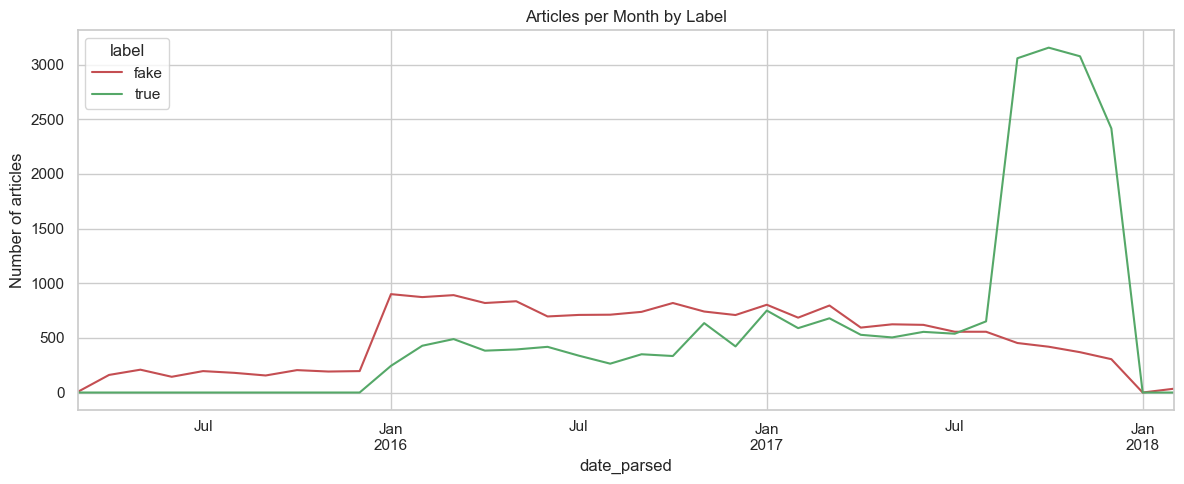

In [47]:
monthly = (df_clean.dropna(subset=["date_parsed"]).set_index("date_parsed").groupby("label").resample("ME").size().unstack(level=0).fillna(0))

monthly.plot(figsize=(12, 5), color={"fake": "#C44E52", "true": "#55A868"})
plt.title("Articles per Month by Label")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()


**Detection implication:** The two classes were collected over different time windows. True articles
only start in January 2016 and surge to about 3,000 a month in late 2017, while fake articles run
steadily from 2015. A model could learn "when was this collected" instead of "is this fake", so date
should be excluded as a feature, just like subject.

## Key Insights

1. **Attribution language is a strong, explainable signal.** True articles use sourcing words
   ("said", "according to") far more often and fake articles tend to assert claims without citing
   a source. This is one of the most practical, human-interpretable signals for detection.
2. **Article length is a weak but usable signal.** True articles run longer on average,
   consistent with substantiated reporting vs. shorter opinion-style fake content.
3. **Near-empty-body articles are disproportionately fake** (~670 fake articles had almost no
   body text). A near-empty body paired with a sensational title is itself a red flag worth
   scoring on.
4. **Source/category metadata is not a safe detection feature on its own** it reflects where
   an article was collected from rather than genuine content, so any detector should be built on
   article text/style, not source labels, to generalize to unseen articles.

## Recommendations

1. **Build a detection approach around content signals**, specifically: attribution density
   (cited sources), article length, and sensational/emotive language in the title vs. body.
2. **Flag articles with little/no body text relative to their title** as higher-risk for manual
   review rather than auto-publishing or auto-trusting.
3. **Avoid relying on source/feed metadata** as a detection feature, it won't generalize to
   new, unseen articles from sources not in this training data.
4. **Validate any detector on a separate, more recent dataset** beyond the 2016-2017 period this
   data covers, to confirm the signals (attribution, length) hold up over time and across topics.

## 11. Conclusion

This EDA combined and cleaned the fake and true news datasets, confirmed a reasonably
balanced class split, and identified that `subject` behaves as a near-perfect
but spurious predictor due to how the two source files were originally collected. Beyond that,
true articles trend longer and more attribution-heavy in style, a small subset of fake articles
carry little usable body text.